In [ ]:
#https://www.kaggle.com/datasets/msambare/fer2013


26
209


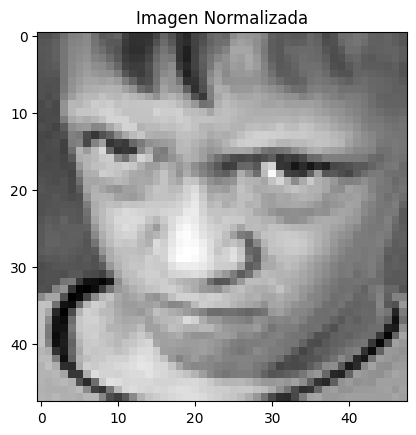

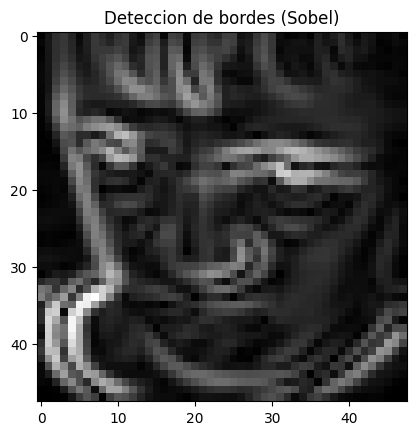

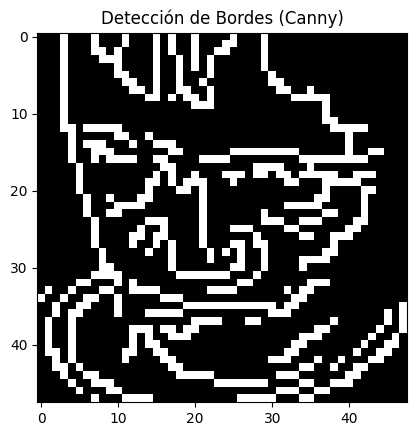

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

image = cv2.imread('/content/Training_89091722.jpg', cv2.IMREAD_GRAYSCALE)

print(np.min(image))
print(np.max(image))

#LO SIGUIENTE NO SE PUEDE HACER DEBIDO A QUE EL RANGO DE LOS PIXELES DE LA IMAGEN ORIGINAL ES DE 10 - 255

image_normalized = (image - np.min(image)) / (np.max(image) - np.min(image))

plt.imshow(image_normalized, cmap='gray')
# plt.imshow(image_normalized, cmap='gray', extent=[0, image.shape[1], image.shape[0], 0])
plt.title('Imagen Normalizada')
plt.show()

# Aplicar Sobel para la detección de bordes
sobelx = cv2.Sobel(image_normalized, cv2.CV_64F, 1, 0, ksize=5)
sobely = cv2.Sobel(image_normalized, cv2.CV_64F, 0, 1, ksize=5)

tin = cv2.magnitude(sobelx, sobely)  # Magnitud de los bordes
plt.imshow(tin, cmap='gray')
plt.title('Deteccion de bordes (Sobel)')
plt.show()


# plt.subplot(1, 2, 1)
# plt.imshow(sobelx, cmap='gray')
# plt.title('Sobel X')

# plt.subplot(1, 2, 2)
# plt.imshow(sobely, cmap='gray')
# plt.title('Sobel Y')

# plt.show()

# # Aplicar el filtro Canny para detectar bordes
edges_canny = cv2.Canny((image_normalized * 255).astype(np.uint8), 100, 200)

plt.imshow(edges_canny, cmap='gray')
plt.title('Detección de Bordes (Canny)')
plt.show()

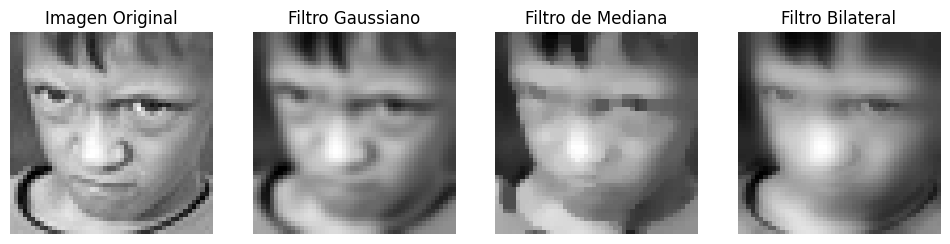

In [ ]:
image_gaussian = cv2.GaussianBlur(image, (5, 5), 0)

image_median = cv2.medianBlur(image, 5)

image_bilateral = cv2.bilateralFilter(image, 9, 75, 75)

plt.figure(figsize=(12, 4))

# Imagen original
plt.subplot(1, 4, 1)
plt.imshow(image, cmap='gray')
plt.title('Imagen Original')
plt.axis('off')

# Imagen con Filtro Gaussiano
plt.subplot(1, 4, 2)
plt.imshow(image_gaussian, cmap='gray')
plt.title('Filtro Gaussiano')
plt.axis('off')

# Imagen con Filtro de Mediana
plt.subplot(1, 4, 3)
plt.imshow(image_median, cmap='gray')
plt.title('Filtro de Mediana')
plt.axis('off')

# Imagen con Filtro Bilateral
plt.subplot(1, 4, 4)
plt.imshow(image_bilateral, cmap='gray')
plt.title('Filtro Bilateral')
plt.axis('off')

plt.show()

In [ ]:
import numpy as np
import cv2

def preprocess_and_extract_features(image):

    image_bilateral = cv2.bilateralFilter(image, 9, 75, 75)

    bilateral_mean = np.mean(image_bilateral)

    sobelx = cv2.Sobel(image_bilateral, cv2.CV_64F, 1, 0, ksize=5)
    sobely = cv2.Sobel(image_bilateral, cv2.CV_64F, 0, 1, ksize=5)
    image_edges = cv2.magnitude(sobelx, sobely)

    edges_mean = np.mean(image_edges)

    return bilateral_mean, edges_mean

#con una imagen
image_path = '/content/Training_89091722.jpg'
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)


bilateral_mean, edges_mean = preprocess_and_extract_features(image)

print(f"Media del filtro bilateral (suavizado): {bilateral_mean}")
print(f"Media de la detección de bordes (Sobel): {edges_mean}")

Media del filtro bilateral (suavizado): 128.6796875
Media de la detección de bordes (Sobel): 678.9199287530432


In [ ]:
# Función para preprocesar las imágenes de una carpeta (50)
#def preprocess_images_in_folder(folder_path, max_images_per_folder=50):
#    features = []
#    labels = []
#
#    # Definir las etiquetas para las carpetas
#    emotion_folders = {'angry': 0, 'happy': 1}
#
#    # Recorrer las carpetas de emociones
#    for emotion, label in emotion_folders.items():
#        emotion_folder = os.path.join(folder_path, emotion)
#
#        print(f"Procesando carpeta: {emotion_folder}")
#        if not os.path.exists(emotion_folder):
#            print(f"Carpeta {emotion_folder} no encontrada")
#            continue
#
#       count = 0
#       for filename in os.listdir(emotion_folder):
#           if filename.endswith('.jpg'):
#               image_path = os.path.join(emotion_folder, filename)
#               image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
#
#               # Aplicar preprocesamiento y obtener características
#               image_features = preprocess_image(image)
#
#                features.append(image_features)
#                labels.append(label)
#
#                count += 1
#
#                # Detenerse después de procesar el número máximo de imágenes
#                if count >= max_images_per_folder:
#                    break
#
#        print(f"Total de imágenes procesadas para {emotion}: {count}")
#
#    return features, labels

# # Procesar imágenes de entrenamiento y prueba
# train_features, train_labels = preprocess_images_in_folder(train_dir)
# test_features, test_labels = preprocess_images_in_folder(test_dir)

# print("\n")
# print(f"Número de imágenes procesadas en train: {len(train_features)}")
# print(f"Número de imágenes procesadas en test: {len(test_features)}")

In [ ]:
#NO ELIMINAR NO EJECUTAR SERVIRA MAS TARDE
#NO ELIMINAR NO EJECUTAR SERVIRA MAS TARDE
#NO ELIMINAR NO EJECUTAR SERVIRA MAS TARDE
#NO ELIMINAR NO EJECUTAR SERVIRA MAS TARDE
#NO ELIMINAR NO EJECUTAR SERVIRA MAS TARDE

# # Función para guardar imágenes y etiquetas preprocesadas
# def save_preprocessed_data(images, labels, prefix='train'):
#     # Convertir a arrays de NumPy si no lo son ya
#     images_array = np.array(images)
#     labels_array = np.array(labels)

#     # Guardar las imágenes y las etiquetas como archivos .npy
#     np.save(f'{prefix}_images.npy', images_array)
#     np.save(f'{prefix}_labels.npy', labels_array)

# # Después de haber procesado las imágenes
# train_images, train_labels = preprocess_images_in_folder(train_dir)
# test_images, test_labels = preprocess_images_in_folder(test_dir)

# # Guardar las imágenes preprocesadas de train y test
# save_preprocessed_data(train_images, train_labels, prefix='train')
# save_preprocessed_data(test_images, test_labels, prefix='test')

# print("Imágenes y etiquetas preprocesadas guardadas correctamente.")



# # Función para cargar imágenes y etiquetas preprocesadas
# def load_preprocessed_data(prefix='train'):
#     images = np.load(f'{prefix}_images.npy')
#     labels = np.load(f'{prefix}_labels.npy')
#     return images, labels

# # Cargar imágenes preprocesadas de train y test
# train_images, train_labels = load_preprocessed_data(prefix='train')
# test_images, test_labels = load_preprocessed_data(prefix='test')

# print("Imágenes y etiquetas preprocesadas cargadas correctamente.")